### Day 23 – Senses: Taste | #30DayMapChallenge

**The Taste of Diversity – Mapping Vienna's Culinary Landscape**

What does culinary diversity look like on a map? Can we measure the variety of tastes a city has to offer, and how does this diversity change across urban space?

For today's challenge, I explored the geography of culinary diversity in Vienna using restaurant locations and their cuisine classifications from OpenStreetMap. Rather than simply mapping where restaurants are located, I wanted to understand how different culinary traditions are distributed throughout the city.

To quantify this diversity, I calculated the **Shannon Diversity Index** for restaurants within a hexagonal grid. The index considers both the number of different cuisines and how evenly they are represented. A high value indicates a diverse and relatively balanced mix of culinary traditions, while a low value suggests that only a few cuisines are represented or that one type dominates.

The resulting map reveals a distinct spatial pattern. Vienna's inner districts emerge as hotspots of culinary diversity, with the highest values concentrated around the city centre. Moving towards the outer districts, the pattern becomes increasingly fragmented, with smaller pockets of diversity surrounded by areas with more limited culinary variety.

What makes this approach interesting is that **restaurant density and culinary diversity are not necessarily the same thing**. An area with many restaurants serving similar food may be less diverse than a neighborhood with fewer restaurants offering a wider range of cuisines.

Of course, the map reflects the cuisine categories recorded in OpenStreetMap rather than the full range of flavors available in Vienna. Nevertheless, it offers a different perspective on the city's urban structure: one defined not by buildings, population, or infrastructure, but by the diversity of food.

**A city's taste is more than the sum of its restaurants. It is the variety of cultures, traditions, and flavors that come together in space.**

#30DayMapChallenge #Day23 #SensesTaste #CulinaryDiversity #ShannonIndex #OpenStreetMap #Vienna #GIS #Python #Cartography

In [48]:
import osmnx as ox
import numpy as np
import geopandas as gpd
from matplotlib import pyplot as plt
from shapely.geometry import Polygon
import pandas as pd


In [2]:
ox.settings.use_cache = True  # Antworten zwischenspeichern
ox.settings.cache_folder = "cache"  # 2026/cache/ gibt es schon
restaurants = ox.features_from_place("Wien, Austria", tags={"amenity": 'restaurant'})

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

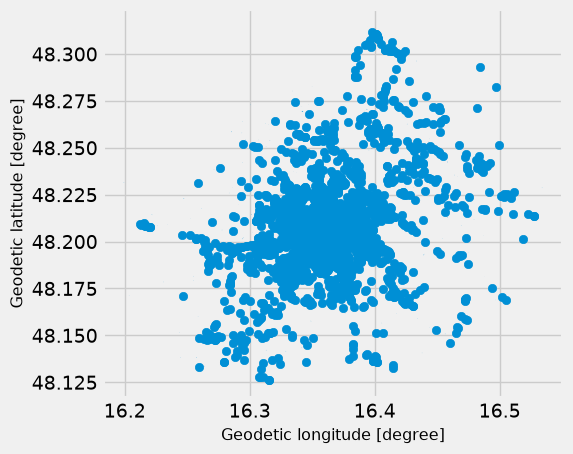

In [3]:
gdf = restaurants
gdf.plot()

In [10]:
print(gdf.columns)
print(len(gdf))

Index(['geometry', 'addr:city', 'addr:country', 'addr:housenumber',
       'addr:postcode', 'addr:street', 'amenity', 'contact:website', 'cuisine',
       'name',
       ...
       'payment:mastercard_contactless', 'payment:unionpay',
       'payment:visa_electron', 'parking', 'parking:note', 'payment:invoice',
       'description:de', 'construction', 'area', 'type'],
      dtype='str', length=377)
3012


In [5]:
print(gdf["cuisine"].unique())

<ArrowStringArray>
[                                     'regional',
                                         'pizza',
                                      'barbecue',
                                             nan,
              'breakfast;regional;international',
                                      'heuriger',
                       'regional;austrian;local',
                                   'steak_house',
                          'pizza;italian;indian',
                                     'levantine',
 ...
            'regional;international;traditional',
                      'kebab;pizza;burger;pasta',
                       'local;austrian;regional',
 'regional;buschenschank;austrian;sausage;local',
       'mexican;indian;breakfast;curry;regional',
                  'vietnamese;asian;thai;fusion',
                             'regional;barbecue',
                          'sushi;japanese;asian',
                       'regional;austrian;grill',
                          

In [8]:
gdf["cuisine"].unique().tolist()

['regional',
 'pizza',
 'barbecue',
 nan,
 'breakfast;regional;international',
 'heuriger',
 'regional;austrian;local',
 'steak_house',
 'pizza;italian;indian',
 'levantine',
 'vietnamese',
 'turkish',
 'austrian',
 'pizza;italian',
 'indian',
 'regional;burger',
 'korean;japanese',
 'chinese',
 'beer',
 'local;regional',
 'italian',
 'austrian;local;regional',
 'asian',
 'korean',
 'japanese',
 'sushi',
 'burger;sandwich',
 'greek',
 'thai',
 'traditional;regional;coffee_shop',
 'regional;heuriger',
 'persian',
 'italian;pizza',
 'mexican',
 'burger',
 'hungarian',
 'austrian;regional',
 'pizza;italian;regional',
 'pizza;italian;pasta',
 'breakfast;coffee_shop;fish;ice_cream;regional;tea',
 'flatbread',
 'regional;international',
 'spanish',
 'sushi;asian',
 'bohemian',
 'israeli',
 '5-Elemente',
 'austrian;czech',
 'sushi;noodle',
 'japanese;ramen',
 'austrian;italian',
 'french',
 'indian;pakistani',
 'sandwich',
 'buschenschank',
 'balkan',
 'fine_dining',
 'serbian;grill',
 'vienn

In [15]:
einzelwerte = sorted({
    teil.strip().lower()
    for eintrag in gdf["cuisine"].unique().tolist()
    if isinstance(eintrag, str)  # überspringt nan
    for teil in eintrag.split(";")
    if teil.strip()
})
print(len(einzelwerte))

173


In [16]:
einzelwerte

['5-elemente',
 'afghan',
 'african',
 'american',
 'antipasti',
 'arab',
 'arabian',
 'argentinian',
 'asian',
 'asian fusion',
 'austrian',
 'azerbaijan',
 'baguette',
 'balkan',
 'bangladeshi',
 'barbecue',
 'beer',
 'bier',
 'bistro',
 'bohemian',
 'bosnian',
 'bowl',
 'bowls',
 'brazilian',
 'breakfast',
 'brunch',
 'bubble_tea',
 'buffet',
 'bulgarian',
 'burger',
 'burritos',
 'buschenschank',
 'cafe',
 'cake',
 'canteen',
 'caribbean',
 'char-grilled',
 'chicken',
 'chinese',
 'coffee',
 'coffee_shop',
 'colombian',
 'cordon_bleu',
 'crepe',
 'croatian',
 'curry',
 'czech',
 'dessert',
 'diner',
 'dumplings',
 'eritrean',
 'escalope',
 'ethiopian',
 'falafel',
 'fast_food',
 'fine_dining',
 'fish',
 'fish_and_chips',
 'fladen',
 'flatbread',
 'focaccia',
 'french',
 'fries',
 'friture',
 'fusion',
 'georgian',
 'german',
 'gourmet',
 'greek',
 'grill',
 'hawaiian',
 'heuriger',
 'hipster',
 'hot_dog',
 'hungarian',
 'ice_cream',
 'indian',
 'indonesian',
 'international',
 'isr

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

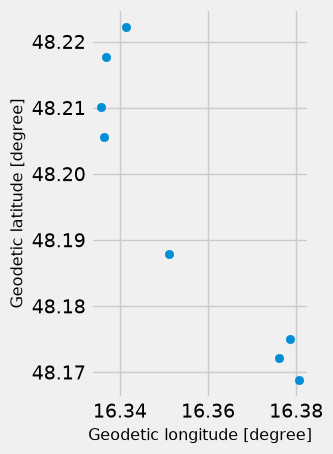

In [32]:
schnitzel = gdf[gdf["cuisine"].str.contains("syrian", case=False)]
schnitzel.plot()

In [39]:
all_restaurants = gpd.GeoDataFrame()

for wert in einzelwerte:
    gdf_t = gdf[gdf["cuisine"].str.contains(wert, case=False)]
    gdf_t["cuisine"] = wert
    all_restaurants = pd.concat([all_restaurants, gdf_t], ignore_index=True)


ValueError: Invalid RGBA argument: np.float64(0.8980392156862745)

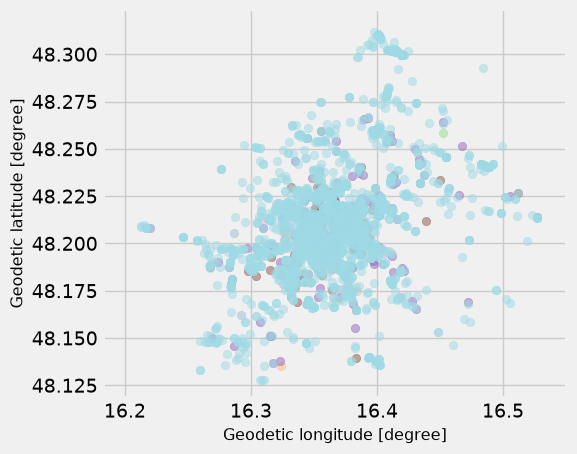

In [47]:
all_restaurants.plot(column="cuisine", categorical=True, alpha=0.5)

In [49]:
def hexgrid(bounds, r, crs):
    """Hexagon-Raster (flache Oberseite) über bounds; r = Kantenlänge = Radius in CRS-Einheiten."""
    xmin, ymin, xmax, ymax = bounds
    dx, dy = 1.5 * r, np.sqrt(3) * r  # Abstand der Spalten / Zeilen
    ang = np.deg2rad(np.arange(0, 360, 60))
    ox, oy = r * np.cos(ang), r * np.sin(ang)  # die 6 Ecken relativ zum Mittelpunkt
    hexes = []
    for i, x in enumerate(np.arange(xmin, xmax + dx, dx)):
        y0 = ymin + (dy / 2 if i % 2 else 0)  # jede zweite Spalte halb versetzt
        for y in np.arange(y0, ymax + dy, dy):
            hexes.append(Polygon(zip(x + ox, y + oy)))
    return gpd.GeoDataFrame(geometry=hexes, crs=crs)

In [55]:
all_restaurants = all_restaurants.to_crs("EPSG:31287")
grid = hexgrid(all_restaurants.total_bounds, r=250, crs=all_restaurants.crs)

In [58]:
j = gpd.sjoin(all_restaurants, grid, predicate="within")
grid["n"] = j.groupby("index_right").size()
grid["n"] = grid["n"].fillna(0).astype(int)


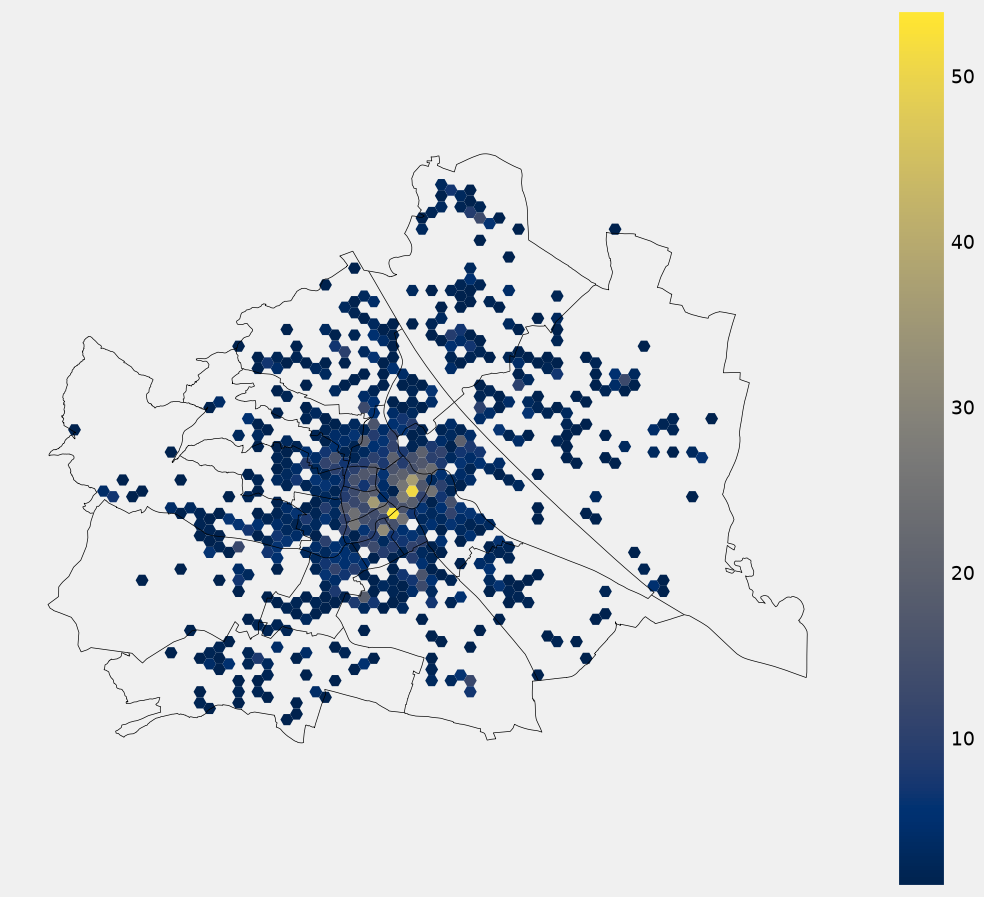

In [75]:
districts = gpd.read_file("data/vienna_districts_lines.geojson")
districts = districts.to_crs(31287)

fig, ax = plt.subplots(figsize=(12, 12))
grid[grid["n"] > 0].plot(ax=ax, column="n", cmap="cividis", legend=True)
districts.plot(ax=ax, linewidth=0.5, edgecolor="black")
ax.set_axis_off()
plt.show()

In [77]:
# 1. Restaurants den Hexagonen zuordnen, ohne Restaurants ohne Küche
j = gpd.sjoin(all_restaurants, grid, predicate="within")[["index_right", "cuisine"]]
j = j.dropna(subset=["cuisine"])

# 2. Mehrfachwerte zerlegen: "italian;pizza" zählt je 0,5 für italian und pizza
j["cuisine"] = j["cuisine"].str.lower().str.split(";")
j["w"] = 1 / j["cuisine"].str.len()
j = j.explode("cuisine")
j["cuisine"] = j["cuisine"].str.strip()

# 3. Anteile p_i je Hexagon und Küche
counts = j.groupby(["index_right", "cuisine"])["w"].sum()
p = counts / counts.groupby(level=0).transform("sum")

# 4. Shannon-Entropie und Kennzahlen dazu
grid["shannon"] = (-(p * np.log(p))).groupby(level=0).sum().clip(lower=0)
grid["n_kuechen"] = counts.groupby(level=0).size()
grid["n_rest"] = gpd.sjoin(all_restaurants, grid, predicate="within").groupby("index_right").size()
grid["evenness"] = grid["shannon"] / np.log(grid["n_kuechen"])  # Pielou, 0–1

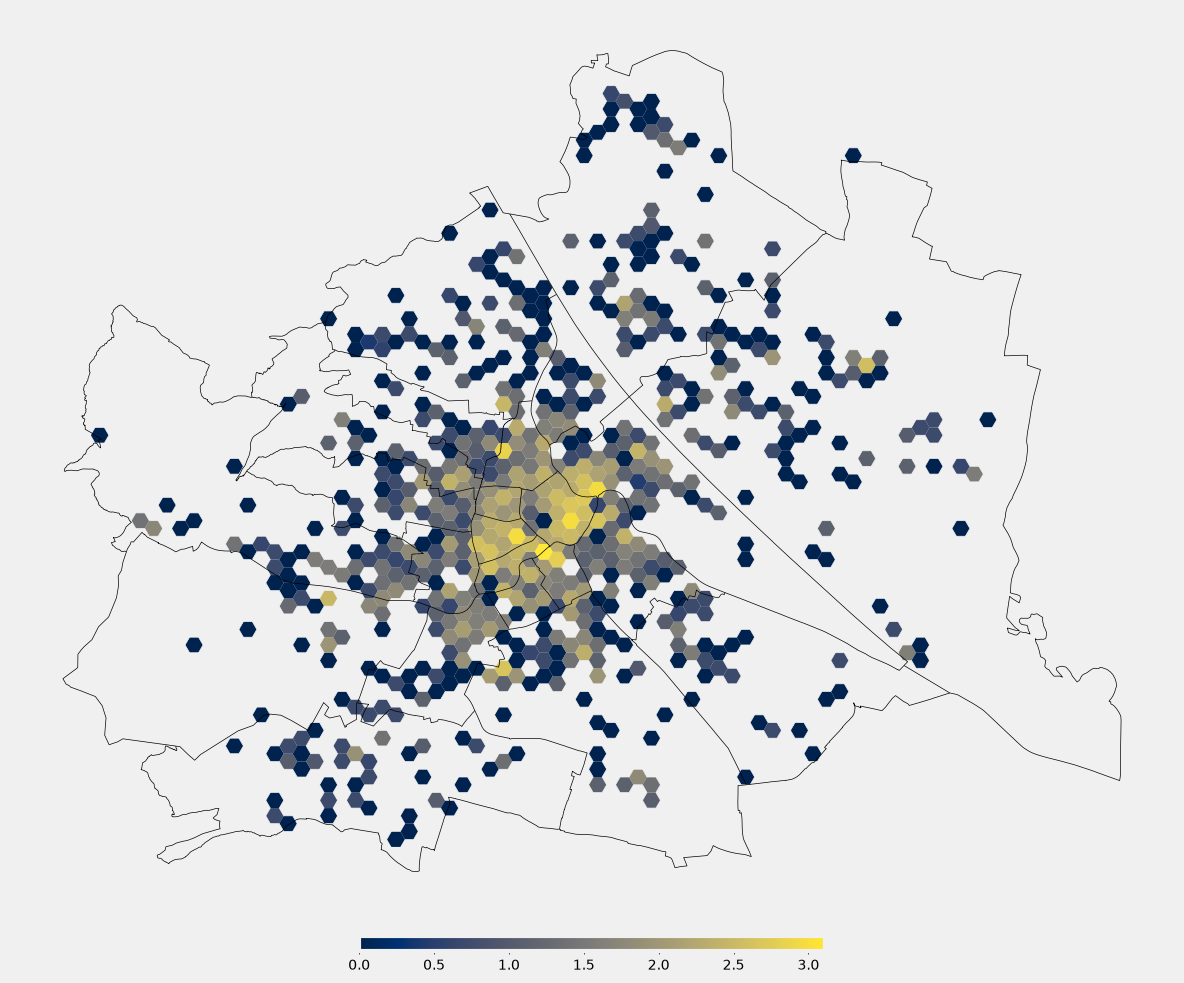

In [121]:
fig, ax = plt.subplots(figsize=(12, 12))
grid.plot(ax=ax, column="shannon", cmap="cividis", legend=True, legend_kwds={
    "orientation": "horizontal", "shrink": 0.4, "aspect": 30, "pad": 0.02},
          missing_kwds={"color": "none"}, figsize=(10, 10))
districts.plot(ax=ax, linewidth=0.5, edgecolor="black")
cbar_ax = fig.axes[-1]
cbar_ax.tick_params(labelsize=10, length=2, width=0.5)  # Zahlen und Tick-Striche
ax.set_axis_off()
plt.tight_layout()
fig.savefig("maps/map23.png", dpi=300, bbox_inches="tight")

